# Phase 2 Task 2: Robustness Tests

**Objective:** Test if model relies on edge features, color, or spatial layout

**Date:** 30-09-2026

**Background:** Grad-CAM shows model focuses on edges - test this hypothesis

## 1. Setup

In [1]:
from pathlib import Path
import sys

CWD = Path.cwd()
for i, part in enumerate(CWD.parts):
    if part == 'woodbench':
        ROOT = Path(*CWD.parts[:i+1])
        break
else:
    ROOT = CWD

sys.path.insert(0, str(ROOT))

import torch
import timm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

print(f"ROOT: {ROOT}")

ROOT: /home/sakana/Code/ManifoldsTeam/woodbench


## 2. Define Robustness Transforms

In [2]:
import torchvision.transforms as T

# Define robustness transforms
class CenterCropTransform:
    """Crop to 70% and resize back - removes edge info"""
    def __init__(self, crop_ratio=0.7, target_size=224):
        self.crop_ratio = crop_ratio
        self.target_size = target_size
    
    def __call__(self, img):
        w, h = img.size
        crop_w = int(w * self.crop_ratio)
        crop_h = int(h * self.crop_ratio)
        left = (w - crop_w) // 2
        top = (h - crop_h) // 2
        img = img.crop((left, top, left + crop_w, top + crop_h))
        return img.resize((self.target_size, self.target_size), Image.BILINEAR)

class EdgeMaskTransform:
    """Mask edges with black border"""
    def __init__(self, border_ratio=0.15, target_size=224):
        self.border_ratio = border_ratio
        self.target_size = target_size
    
    def __call__(self, img):
        img = img.resize((self.target_size, self.target_size))
        arr = np.array(img).astype(np.float32)
        border = int(self.target_size * self.border_ratio)
        arr[:border, :] = 0
        arr[-border:, :] = 0
        arr[:, :border] = 0
        arr[:, -border:] = 0
        return Image.fromarray(arr.astype(np.uint8))

class GrayscaleTransform:
    """Convert to grayscale - removes color info"""
    def __call__(self, img):
        gray = img.convert('L')
        return Image.merge('RGB', [gray, gray, gray])

class RandomCropTransform:
    """Random crop at 70% - tests spatial invariance"""
    def __init__(self, crop_ratio=0.7, target_size=224):
        self.crop_ratio = crop_ratio
        self.target_size = target_size
    
    def __call__(self, img):
        w, h = img.size
        crop_w = int(w * self.crop_ratio)
        crop_h = int(h * self.crop_ratio)
        left = np.random.randint(0, w - crop_w + 1)
        top = np.random.randint(0, h - crop_h + 1)
        img = img.crop((left, top, left + crop_w, top + crop_h))
        return img.resize((self.target_size, self.target_size), Image.BILINEAR)

print("Transform classes defined.")

Transform classes defined.


## 3. Compose Transforms with Normalization

In [3]:
# Compose transforms with normalization
NORMALIZE = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

def make_transform(name, target_size=224):
    """Create transform pipeline for robustness test."""
    transforms = []
    
    if name == 'baseline':
        transforms = [
            T.Resize((target_size, target_size)),
        ]
    elif name == 'center_crop_70':
        transforms = [
            CenterCropTransform(crop_ratio=0.7, target_size=target_size),
        ]
    elif name == 'edge_mask_15':
        transforms = [
            EdgeMaskTransform(border_ratio=0.15, target_size=target_size),
        ]
    elif name == 'grayscale':
        transforms = [
            T.Resize((target_size, target_size)),
            GrayscaleTransform(),
        ]
    elif name == 'random_crop_70':
        transforms = [
            RandomCropTransform(crop_ratio=0.7, target_size=target_size),
        ]
    
    transforms.extend([
        T.ToTensor(),
        NORMALIZE
    ])
    
    return T.Compose(transforms)

# Define all tests
ROBUSTNESS_TESTS = {
    'baseline': 'Standard resize to 224x224',
    'center_crop_70': 'Center crop to 70%, resize back (removes edge info)',
    'edge_mask_15': 'Mask 15% border with black (removes edge features)',
    'grayscale': 'Convert to grayscale (removes color info)',
    'random_crop_70': 'Random crop at 70% (tests spatial invariance)',
}

for name, desc in ROBUSTNESS_TESTS.items():
    print(f"{name}: {desc}")

baseline: Standard resize to 224x224
center_crop_70: Center crop to 70%, resize back (removes edge info)
edge_mask_15: Mask 15% border with black (removes edge features)
grayscale: Convert to grayscale (removes color info)
random_crop_70: Random crop at 70% (tests spatial invariance)


## 4. Visualize Transforms

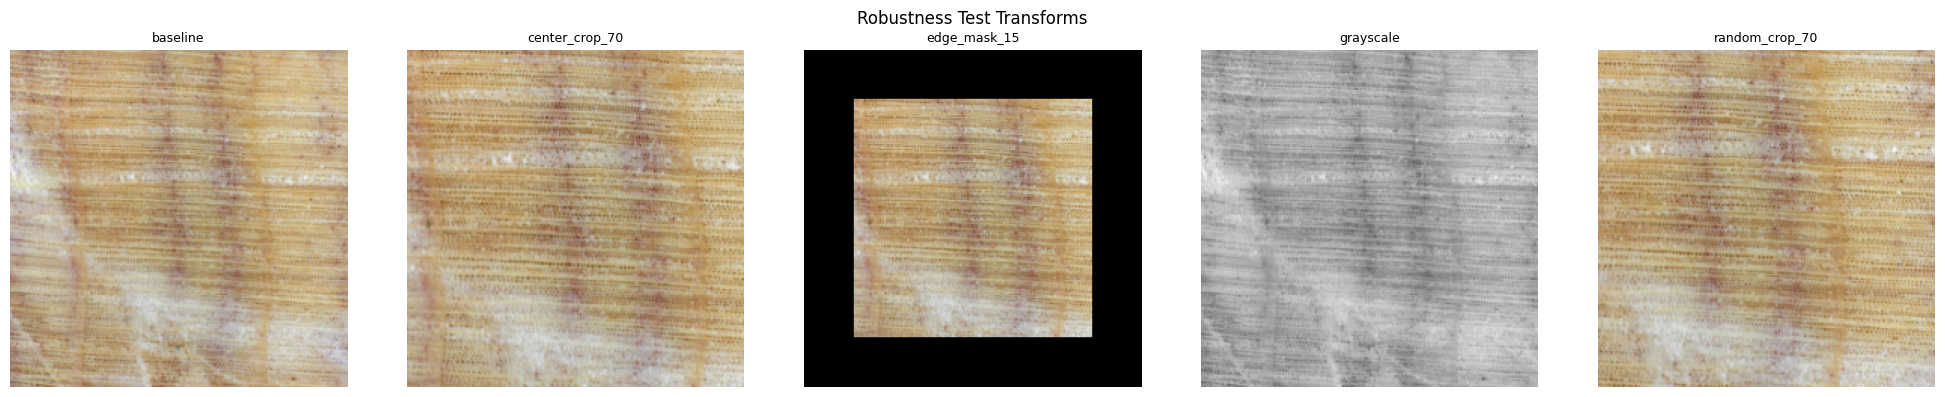

In [4]:
# Load a sample image
sample_paths = list((ROOT / "data/task-B-group-split/train").glob("**/*.png"))[:1]
if sample_paths:
    sample_img = Image.open(sample_paths[0]).convert('RGB')
    
    n = len(ROBUSTNESS_TESTS)
    fig, axes = plt.subplots(1, n, figsize=(4*n, 4))
    
    for idx, (name, desc) in enumerate(ROBUSTNESS_TESTS.items()):
        transform = make_transform(name)
        transformed = transform(sample_img)
        
        # Denormalize for display
        img_display = transformed.permute(1, 2, 0).numpy()
        img_display = img_display * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
        img_display = np.clip(img_display, 0, 1)
        
        axes[idx].imshow(img_display)
        axes[idx].set_title(name, fontsize=9)
        axes[idx].axis('off')
    
    plt.suptitle('Robustness Test Transforms')
    plt.tight_layout()
    plt.savefig('robustness_transforms.png', dpi=150)
    plt.show()

## 5. Load Model and Dataset

In [5]:
# Load ConvNeXt-Tiny checkpoint
CHECKPOINT = ROOT / "data/experiments/Task-B-new/19-08-2026/main/seed_42/convnext_tiny/convnext_tiny_seed42_best.pth"

# Load checkpoint (contains training metadata)
checkpoint = torch.load(CHECKPOINT, map_location='cpu')

# Extract model state dict
if 'model_state_dict' in checkpoint:
    state_dict = checkpoint['model_state_dict']
    print(f"Loaded checkpoint: epoch={checkpoint.get('epoch')}, acc={checkpoint.get('best_val_acc')}")
else:
    state_dict = checkpoint
    print("Loaded pure state dict")

model = timm.create_model('convnext_tiny', pretrained=False, num_classes=17)
model.load_state_dict(state_dict)
model = model.cuda()
model.eval()

print(f"Loaded ConvNeXt-Tiny from {CHECKPOINT}")

# Load test set
from torch.utils.data import Dataset, DataLoader

class TestDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.samples = []
        self.transform = transform
        
        classes = sorted([d.name for d in (root_dir).iterdir() if d.is_dir()])
        self.class_to_idx = {c: i for i, c in enumerate(classes)}
        self.idx_to_class = {i: c for c, i in self.class_to_idx.items()}
        
        for class_dir in sorted((root_dir).iterdir()):
            if class_dir.is_dir():
                for img_path in class_dir.glob("*.png"):
                    self.samples.append((str(img_path), self.class_to_idx[class_dir.name]))
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label, path

test_dir = ROOT / "data/task-B-group-split/test"
test_dataset = TestDataset(test_dir)
print(f"Test set: {len(test_dataset)} samples, {len(test_dataset.class_to_idx)} classes")

Loaded checkpoint: epoch=13, acc=99.88925802879291
Loaded ConvNeXt-Tiny from /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/Task-B-new/19-08-2026/main/seed_42/convnext_tiny/convnext_tiny_seed42_best.pth
Test set: 532 samples, 17 classes


## 6. Run Robustness Evaluation

In [6]:
from sklearn.metrics import accuracy_score

results = []

for test_name, desc in ROBUSTNESS_TESTS.items():
    print(f"\n=== Testing: {test_name} ({desc}) ===")
    
    transform = make_transform(test_name)
    test_dataset.transform = transform
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    
    all_preds = []
    all_labels = []
    
    for images, labels, _ in tqdm(test_loader, desc=test_name):
        images = images.cuda()
        
        with torch.no_grad():
            outputs = model(images)
            preds = outputs.argmax(dim=1).cpu().numpy()
        
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())
    
    acc = accuracy_score(all_labels, all_preds)
    results.append({
        'test': test_name,
        'description': desc,
        'accuracy': acc,
        'drop_from_baseline': None
    })
    
    print(f"  Accuracy: {acc:.4f} ({acc*100:.2f}%)")


=== Testing: baseline (Standard resize to 224x224) ===


baseline:   0%|          | 0/17 [00:00<?, ?it/s]

  Accuracy: 0.9981 (99.81%)

=== Testing: center_crop_70 (Center crop to 70%, resize back (removes edge info)) ===


center_crop_70:   0%|          | 0/17 [00:00<?, ?it/s]

  Accuracy: 0.9774 (97.74%)

=== Testing: edge_mask_15 (Mask 15% border with black (removes edge features)) ===


edge_mask_15:   0%|          | 0/17 [00:00<?, ?it/s]

  Accuracy: 0.9944 (99.44%)

=== Testing: grayscale (Convert to grayscale (removes color info)) ===


grayscale:   0%|          | 0/17 [00:00<?, ?it/s]

  Accuracy: 0.7368 (73.68%)

=== Testing: random_crop_70 (Random crop at 70% (tests spatial invariance)) ===


random_crop_70:   0%|          | 0/17 [00:00<?, ?it/s]

  Accuracy: 0.9793 (97.93%)


## 7. Analyze Results

In [7]:
results_df = pd.DataFrame(results)

# Calculate drop from baseline
baseline_acc = results_df[results_df['test'] == 'baseline']['accuracy'].values[0]
results_df['drop_from_baseline'] = baseline_acc - results_df['accuracy']

print("\n" + "="*70)
print("ROBUSTNESS TEST RESULTS")
print("="*70)
print(f"\nBaseline accuracy: {baseline_acc:.4f} ({baseline_acc*100:.2f}%)")

print("\n--- Results ---")
for _, row in results_df.iterrows():
    if row['test'] != 'baseline':
        drop = row['drop_from_baseline']
        print(f"\n{row['test']}:")
        print(f"  Description: {row['description']}")
        print(f"  Accuracy: {row['accuracy']:.4f} ({row['accuracy']*100:.2f}%)")
        print(f"  Drop: {drop:.4f} ({drop*100:+.2f}%)")
        
        # Interpretation
        if 'edge' in row['test'] and drop > 0.02:
            print(f"  ⚠️  Model relies on edge features")
        if 'gray' in row['test'] and drop > 0.02:
            print(f"  ⚠️  Model relies on color")
        if 'crop' in row['test'] and drop > 0.02:
            print(f"  ⚠️  Model relies on spatial layout")


ROBUSTNESS TEST RESULTS

Baseline accuracy: 0.9981 (99.81%)

--- Results ---

center_crop_70:
  Description: Center crop to 70%, resize back (removes edge info)
  Accuracy: 0.9774 (97.74%)
  Drop: 0.0207 (+2.07%)
  ⚠️  Model relies on spatial layout

edge_mask_15:
  Description: Mask 15% border with black (removes edge features)
  Accuracy: 0.9944 (99.44%)
  Drop: 0.0038 (+0.38%)

grayscale:
  Description: Convert to grayscale (removes color info)
  Accuracy: 0.7368 (73.68%)
  Drop: 0.2613 (+26.13%)
  ⚠️  Model relies on color

random_crop_70:
  Description: Random crop at 70% (tests spatial invariance)
  Accuracy: 0.9793 (97.93%)
  Drop: 0.0188 (+1.88%)


## 8. Visualize Results

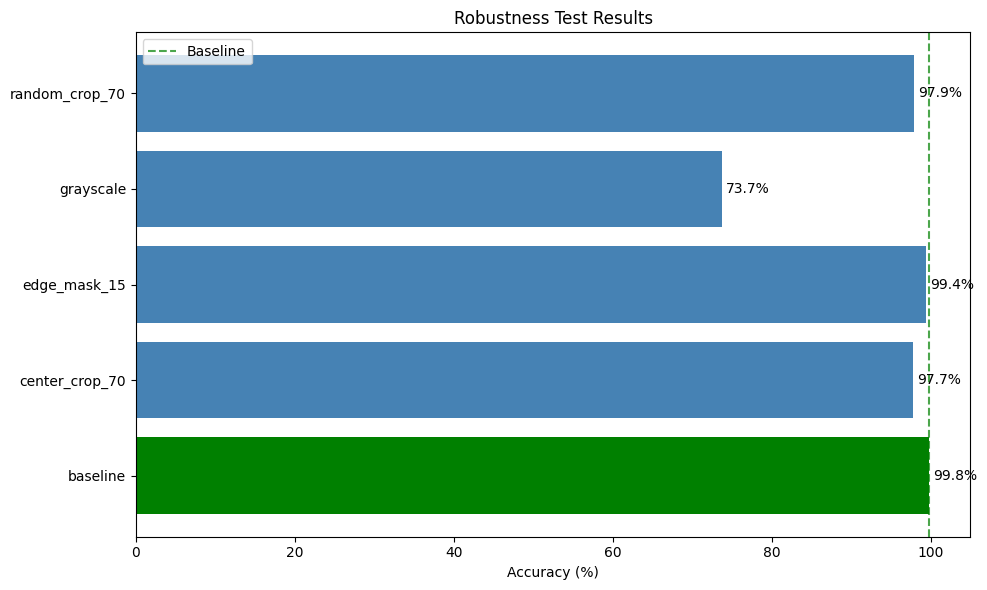

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

tests = results_df['test'].values
accuracies = results_df['accuracy'].values * 100
colors = ['green' if t == 'baseline' else 'steelblue' for t in tests]

bars = ax.barh(tests, accuracies, color=colors)

# Add value labels
for bar, acc in zip(bars, accuracies):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, 
            f'{acc:.1f}%', va='center')

ax.set_xlabel('Accuracy (%)')
ax.set_title('Robustness Test Results')
ax.set_xlim(0, 105)
ax.axvline(x=baseline_acc*100, color='green', linestyle='--', alpha=0.7, label='Baseline')
ax.legend()

plt.tight_layout()
plt.savefig('robustness_results.png', dpi=150)
plt.show()

## 9. Conclusions

In [9]:
print("""
============================================================
ROBUSTNESS TEST CONCLUSIONS
============================================================

Key Findings:

""")

for _, row in results_df.iterrows():
    if row['test'] != 'baseline':
        drop = row['drop_from_baseline'] * 100
        if drop > 5:
            print(f"• {row['test']}: Major drop ({drop:+.1f}%) - model relies on this feature")
        elif drop > 2:
            print(f"• {row['test']}: Moderate drop ({drop:+.1f}%) - model uses this feature somewhat")
        else:
            print(f"• {row['test']}: Minimal drop ({drop:+.1f}%) - model is robust")

print("""
============================================================

Implications for Paper:
1. Edge reliance: If edge_mask causes large drop, discuss what features model uses
2. Color reliance: If grayscale causes large drop, discuss role of color
3. Spatial layout: If crops cause large drop, discuss learned spatial patterns

These findings support the Discussion section on model interpretation.
============================================================
""")

# Save
results_df.to_csv('robustness_results.csv', index=False)
print("Saved: robustness_results.csv")


ROBUSTNESS TEST CONCLUSIONS

Key Findings:


• center_crop_70: Moderate drop (+2.1%) - model uses this feature somewhat
• edge_mask_15: Minimal drop (+0.4%) - model is robust
• grayscale: Major drop (+26.1%) - model relies on this feature
• random_crop_70: Minimal drop (+1.9%) - model is robust


Implications for Paper:
1. Edge reliance: If edge_mask causes large drop, discuss what features model uses
2. Color reliance: If grayscale causes large drop, discuss role of color
3. Spatial layout: If crops cause large drop, discuss learned spatial patterns

These findings support the Discussion section on model interpretation.

Saved: robustness_results.csv
